# ARTI 502 – Deep Learning: Assignment 1

In [6]:
   # Fix: prevents the kernel crash caused by the OpenMP DLL conflict
   import os
   os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [7]:
# Install torchvision and matplotlib into the current kernel's environment
%pip install torchvision matplotlib

Note: you may need to restart the kernel to use updated packages.


## Task 1: Import PyTorch and verify the installation

In [8]:
# Task 1: Import PyTorch and verify the installation

import torch
import torchvision

print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)

print("PyTorch loaded successfully!")

PyTorch Version: 2.14.1
Torchvision Version: 0.29.1
PyTorch loaded successfully!


## Task 2: Download and load the MNIST dataset using torchvision

In [9]:
# Task 2: Download and load the MNIST dataset using torchvision

from torchvision import datasets, transforms

# Convert images into PyTorch tensors
transform = transforms.ToTensor()

# Download and load the training dataset
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download and load the test dataset
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("MNIST Dataset Loaded Successfully!")
print("Training Dataset Size:", len(train_dataset))
print("Testing Dataset Size:", len(test_dataset))

100%|██████████████████████████████████████| 9.91M/9.91M [00:02<00:00, 4.30MB/s]
100%|███████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 167kB/s]
100%|███████████████████████████████████████| 1.65M/1.65M [00:01<00:00, 926kB/s]
100%|██████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 8.07MB/s]

MNIST Dataset Loaded Successfully!
Training Dataset Size: 60000
Testing Dataset Size: 10000


In [10]:

from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)


## Task 3: Inspect the Dataset

In this task, we use a `DataLoader` to load the MNIST images into tensors in mini-batches of 32 images. We then inspect:

1. **Images tensor size**: the shape of one mini-batch of images, in the format **(N × C × H × W)**:
   - **N**: number of images in the batch (batch size = 32)
   - **C**: number of color channels (1, because MNIST is grayscale)
   - **H**: image height in pixels (28)
   - **W**: image width in pixels (28)
2. **Data images visualization**: a sample of the handwritten digits plotted using `matplotlib`, with their true labels.

In [11]:
# Task 3.1: Find the images tensor size

# Get one mini-batch from the training loader
images, labels = next(iter(train_loader))

print("Images tensor size (N x C x H x W):", images.size())
print("Labels tensor size:", labels.size())
print("Single image tensor size:", images[0].size())
print("Data type:", images.dtype)
print("Pixel value range: min =", images.min().item(), ", max =", images.max().item())
print("Labels in this batch:", labels.tolist())

Images tensor size (N x C x H x W): torch.Size([32, 1, 28, 28])
Labels tensor size: torch.Size([32])
Single image tensor size: torch.Size([1, 28, 28])
Data type: torch.float32
Pixel value range: min = 0.0 , max = 1.0
Labels in this batch: [8, 7, 0, 6, 8, 3, 8, 2, 9, 6, 7, 2, 0, 8, 6, 9, 4, 1, 0, 1, 1, 8, 1, 2, 8, 3, 7, 2, 8, 1, 1, 2]


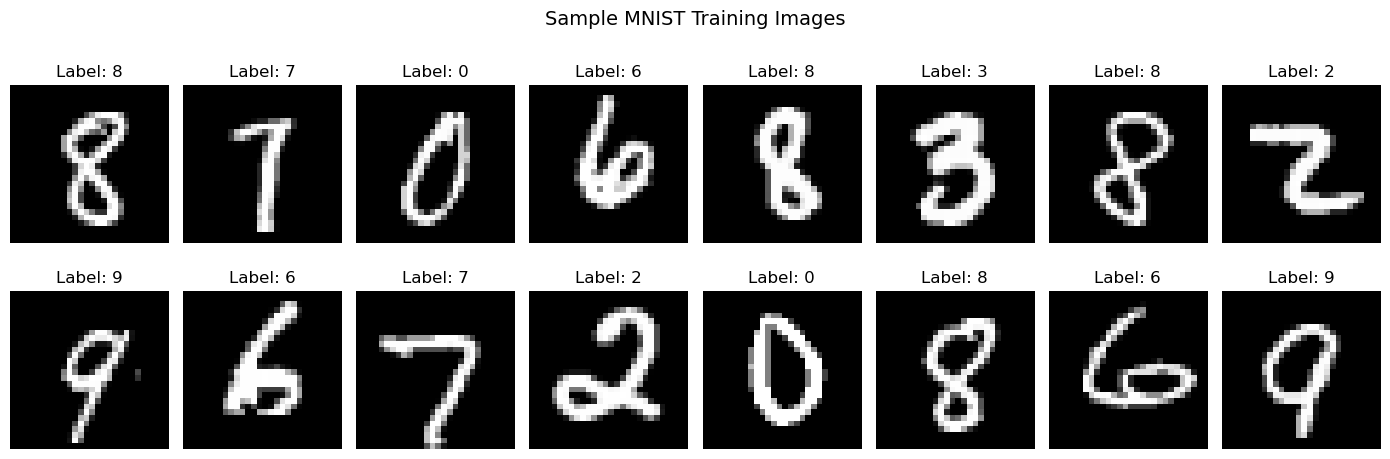

In [12]:
# Task 3.2: Data images visualization using matplotlib

import matplotlib.pyplot as plt

# Plot the first 16 images of the batch with their labels
fig, axes = plt.subplots(2, 8, figsize=(14, 5))

for i, ax in enumerate(axes.flat):
    # Remove the channel dimension: (1, 28, 28) -> (28, 28)
    ax.imshow(images[i].squeeze().numpy(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.suptitle("Sample MNIST Training Images", fontsize=14)
plt.tight_layout()
plt.show()

### Task 3 Results

- One mini-batch of images has the size **[32, 1, 28, 28]**: 32 images, 1 grayscale channel, and 28 × 28 pixels.
- The labels tensor has the size **[32]**, which is one digit label (0–9) per image.
- `transforms.ToTensor()` scaled the pixel values to the range **[0, 1]**.
- The visualization shows that each image is a handwritten digit that matches its label.

## Task 4: Creating a Simple Network

We build a basic neural network with **one hidden layer**:

| Layer | Type | Input → Output | Activation |
|---|---|---|---|
| Flatten | `torch.flatten` | (N × 1 × 28 × 28) → (N × 784) | – |
| Hidden layer (`fc1`) | Fully connected (`nn.Linear`) | 784 → 128 | ReLU |
| Output layer (`fc2`) | Fully connected (`nn.Linear`) | 128 → 10 | None (raw scores) |

- `nn.Linear` layers expect a **2D input (N × I)**: N is the number of images in the mini-batch and I is the number of inputs. Our data is in the shape **(N × C × H × W)**, so we use `torch.flatten(x, 1)` to rearrange it. This flattens every dimension except the batch dimension, so **(32 × 1 × 28 × 28)** becomes **(32 × 784)**.
- **ReLU** is applied to the hidden neurons as the nonlinearity.
- The output layer has **10 neurons**, one for each digit class (0–9). No softmax is added here because `nn.CrossEntropyLoss`, which we use in training, applies it internally.

In [13]:
# Task 4: Creating a Simple Network

import torch.nn as nn
import torch.nn.functional as F

class SimpleNet(nn.Module):
    def __init__(self, input_size=784, hidden_size=128, output_size=10):
        super().__init__()
        # Fully connected layer: input pixels (784) -> hidden neurons
        self.fc1 = nn.Linear(input_size, hidden_size)
        # Fully connected layer: hidden neurons -> output classes (10 digits)
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # Flatten (N x 1 x 28 x 28) -> (N x 784), keeping the batch dimension
        x = torch.flatten(x, 1)
        # Hidden layer with ReLU activation
        x = F.relu(self.fc1(x))
        # Output layer (raw scores / logits)
        x = self.fc2(x)
        return x

# Create the network
net = SimpleNet()
print(net)

SimpleNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [14]:
# Task 4: Verify the network with the requirements

# 1) Shape of the data before flattening
print("Input batch shape (N x C x H x W):", images.shape)

# 2) Shape after torch.flatten
flat_images = torch.flatten(images, 1)
print("Shape after torch.flatten (N x I):", flat_images.shape)

# 3) Forward pass through the network (no training yet)
with torch.no_grad():
    hidden = F.relu(net.fc1(flat_images))
    outputs = net(images)

print("Hidden layer output shape:", hidden.shape)
print("Network output shape (N x classes):", outputs.shape)
print("ReLU check - minimum hidden value:", hidden.min().item())

# 4) Number of trainable parameters
total_params = sum(p.numel() for p in net.parameters() if p.requires_grad)
print("Total trainable parameters:", total_params)

Input batch shape (N x C x H x W): torch.Size([32, 1, 28, 28])
Shape after torch.flatten (N x I): torch.Size([32, 784])
Hidden layer output shape: torch.Size([32, 128])
Network output shape (N x classes): torch.Size([32, 10])
ReLU check - minimum hidden value: 0.0
Total trainable parameters: 101770


### Task 4 Verification

| Requirement | How it is met |
|---|---|
| Single hidden layer | `fc1` (784 → 128) is the only hidden layer |
| Fully connected input → hidden | `nn.Linear(784, 128)` |
| Fully connected hidden → output | `nn.Linear(128, 10)` |
| ReLU on hidden neurons | `F.relu(self.fc1(x))`; the minimum hidden value is 0 |
| Flatten with `torch.flatten` | (32 × 1 × 28 × 28) → (32 × 784) |

The network has **101,770** trainable parameters, and for a batch of 32 images it outputs one score per digit class: **(32 × 10)**.

## Task 5: Training Function

The training function is designed to train the neural network
using the MNIST dataset.

- Loss Function: CrossEntropyLoss
- Optimizer: Stochastic Gradient Descent (SGD)
- Learning Rate: 0.01
- Momentum: 0.9
- Epochs: 5

The function performs forward propagation, calculates the loss,
computes gradients using backpropagation, and updates model
weights using SGD.

It also calculates training accuracy and records loss values
for later visualization in Task 6.


In [15]:

# Task 5 - Cell 1: Import Libraries

import torch
import torch.nn as nn
import torch.optim as optim


In [16]:

# Task 5 - Cell 2: Training Function

def train(net, train_loader, epochs=5, learning_rate=0.01, momentum=0.9):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        net.parameters(),
        lr=learning_rate,
        momentum=momentum
    )

    batch_losses = []
    epoch_losses = []
    epoch_accuracies = []

    for epoch in range(epochs):
        net.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for batch_idx, (images, labels) in enumerate(train_loader):

            optimizer.zero_grad()

            outputs = net(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            predictions = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predictions == labels).sum().item()

            batch_losses.append(loss.item())
            running_loss += loss.item()

            if (batch_idx + 1) % 100 == 0:
                accuracy = 100 * correct / total

                print(
                    f"Epoch [{epoch+1}/{epochs}], "
                    f"Batch [{batch_idx+1}/{len(train_loader)}], "
                    f"Loss: {loss.item():.4f}, "
                    f"Accuracy: {accuracy:.2f}%"
                )

        avg_loss = running_loss / len(train_loader)
        accuracy = 100 * correct / total

        epoch_losses.append(avg_loss)
        epoch_accuracies.append(accuracy)

        print(
            f"Epoch {epoch+1}/{epochs} completed - "
            f"Loss: {avg_loss:.4f}, "
            f"Accuracy: {accuracy:.2f}%"
        )

    return batch_losses, epoch_losses, epoch_accuracies


In [17]:
# Task 5 - Cell 3: Verify Function

print("Training function defined successfully!")
print("Function name:", train.__name__)

Training function defined successfully!
Function name: train


In [18]:

# Task 5 - Cell 4: Check Parameters

import inspect

print(inspect.signature(train))


(net, train_loader, epochs=5, learning_rate=0.01, momentum=0.9)


## Task 6: Training Network 

In this task, we train the SimpleNet neural network using the MNIST training dataset and the training function defined in Task 5.

The training process updates the network weights and records the loss and accuracy to evaluate its performance.


In [19]:
# Task 6: Training Network

net = SimpleNet()

batch_losses, epoch_losses, epoch_accuracies = train(
    net,
    train_loader,
    epochs=5,
    learning_rate=0.01,
    momentum=0.9
)

Epoch [1/5], Batch [100/1875], Loss: 0.8270, Accuracy: 63.22%
Epoch [1/5], Batch [200/1875], Loss: 0.5614, Accuracy: 74.70%
Epoch [1/5], Batch [300/1875], Loss: 0.4117, Accuracy: 79.07%
Epoch [1/5], Batch [400/1875], Loss: 0.2752, Accuracy: 81.59%
Epoch [1/5], Batch [500/1875], Loss: 0.2995, Accuracy: 83.21%
Epoch [1/5], Batch [600/1875], Loss: 0.5228, Accuracy: 84.41%
Epoch [1/5], Batch [700/1875], Loss: 0.3117, Accuracy: 85.45%
Epoch [1/5], Batch [800/1875], Loss: 0.4819, Accuracy: 86.18%
Epoch [1/5], Batch [900/1875], Loss: 0.2365, Accuracy: 86.85%
Epoch [1/5], Batch [1000/1875], Loss: 0.1214, Accuracy: 87.42%
Epoch [1/5], Batch [1100/1875], Loss: 0.2516, Accuracy: 87.90%
Epoch [1/5], Batch [1200/1875], Loss: 0.2106, Accuracy: 88.36%
Epoch [1/5], Batch [1300/1875], Loss: 0.2776, Accuracy: 88.79%
Epoch [1/5], Batch [1400/1875], Loss: 0.0986, Accuracy: 89.02%
Epoch [1/5], Batch [1500/1875], Loss: 0.2048, Accuracy: 89.28%
Epoch [1/5], Batch [1600/1875], Loss: 0.0736, Accuracy: 89.56%
E

### _______________________________________________________________________________________________________________

### Task 6.1: Training Loss and Accuracy

We plot the training loss and accuracy for each epoch to visualize the network's learning progress and evaluate its performance during training.

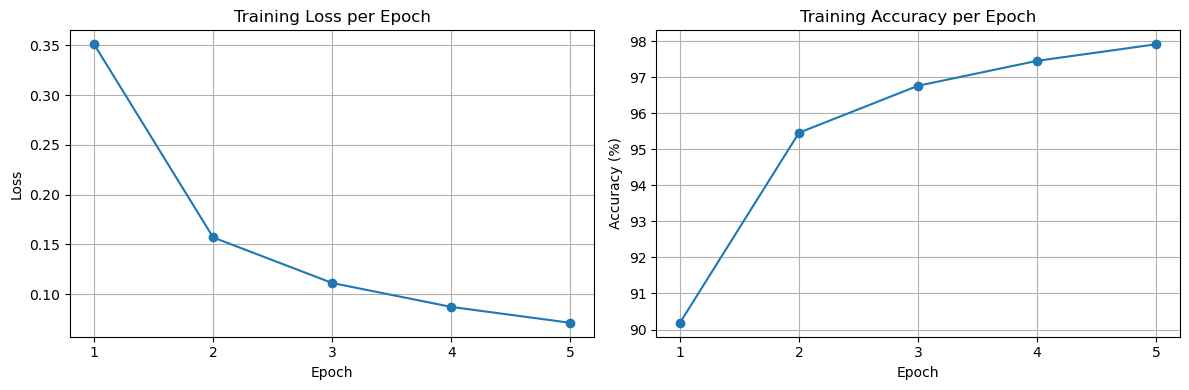

In [20]:
# Task 6.1: Training Loss and Accuracy

import matplotlib.pyplot as plt

epochs = range(1, len(epoch_losses) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, epoch_losses, marker='o')
plt.title("Training Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, epoch_accuracies, marker='o')
plt.title("Training Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs)
plt.grid(True)

plt.tight_layout()
plt.show()

### Task 6.1: Training Performance Analysis
The graphs show a consistent decrease in training loss and an increase in training accuracy across the 5 epochs, indicating that the network is learning effectively.

### _______________________________________________________________________________________________________________

## Task 7: Testing Network

In this task, we evaluated the trained neural network using the MNIST test dataset.

We used `net.eval()` and `torch.no_grad()` to perform testing without updating the model weights.

The test accuracy is calculated by comparing the predicted labels with the actual labels.

In [21]:
# Task 7: Testing Network

net.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = net(images)
        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Correct Predictions: {correct}/{total}")

Test Accuracy: 97.28%
Correct Predictions: 9728/10000


### Task 7.1: Visualize Test Predictions
We displayd 10 sample images from the MNIST test dataset along with their actual labels and the labels predicted by the trained network.

This allows us to visually compare the predictions with the correct answers.

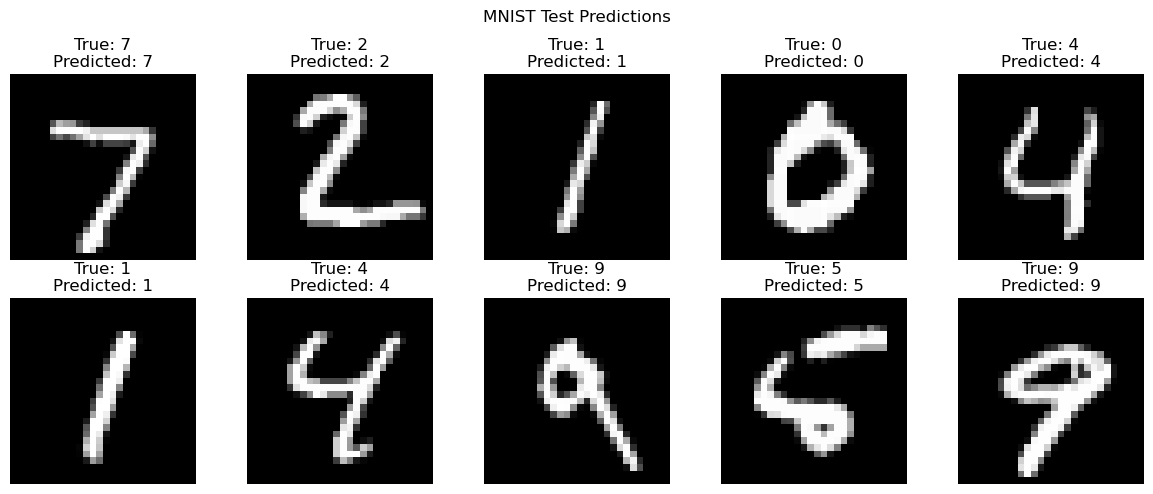

In [22]:
# Task 7.1: Visualize Test Predictions

images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = net(images)
    predictions = outputs.argmax(dim=1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze().numpy(), cmap="gray")

    ax.set_title(
        f"True: {labels[i].item()}\n"
        f"Predicted: {predictions[i].item()}"
    )

    ax.axis("off")

plt.suptitle("MNIST Test Predictions")
plt.tight_layout()
plt.show()

## Task 8: Tuning the Parameters and Model Architecture

In this task, we test different learning rates, momentum values, and network architectures to compare training loss and accuracy.


In [23]:
# Task 8 - Cell 1: Hyperparameter Values
learning_rates = [0.01, 0.05]
momentums = [0.5, 0.9]
results = []


In [24]:
# Task 8 - Cell 2: Learning Rate and Momentum Tuning
# Keep the output short while using the same training function from Task 5.
import io
from contextlib import redirect_stdout

for lr in learning_rates:
    for mom in momentums:
        model = SimpleNet()
        with redirect_stdout(io.StringIO()):
            _, losses, accuracies = train(model, train_loader, epochs=5,
                                         learning_rate=lr, momentum=mom)
        results.append([lr, mom, losses[-1], accuracies[-1]])

print("Learning Rate | Momentum | Loss | Accuracy")
for lr, mom, loss, accuracy in results:
    print(f"{lr:<13} | {mom:<8} | {loss:.4f} | {accuracy:.2f}%")


Learning Rate | Momentum | Loss | Accuracy
0.01          | 0.5      | 0.1951 | 94.51%
0.01          | 0.9      | 0.0736 | 97.86%
0.05          | 0.5      | 0.0741 | 97.89%
0.05          | 0.9      | 0.0484 | 98.44%


In [25]:
# Task 8 - Cell 3: Best Hyperparameters
best_parameters = sorted(results, key=lambda r: (-r[3], r[2]))[0]
print(f"Best learning rate: {best_parameters[0]}")
print(f"Best momentum: {best_parameters[1]}")
print(f"Training loss: {best_parameters[2]:.4f}")
print(f"Training accuracy: {best_parameters[3]:.2f}%")


Best learning rate: 0.05
Best momentum: 0.9
Training loss: 0.0484
Training accuracy: 98.44%


### Task 8.1: Model Architecture Tuning

We compare networks with different numbers of hidden layers and neurons using the best learning rate and momentum from the previous experiment.


In [26]:
# Task 8 - Cell 4: Different Network Architectures
# Same fully connected layers and ReLU activation as Task 4.
class TunedNet(nn.Module):
    def __init__(self, hidden_size=128, hidden_layers=1):
        super().__init__()
        layers = [nn.Flatten(), nn.Linear(784, hidden_size), nn.ReLU()]
        if hidden_layers == 2:
            layers += [nn.Linear(hidden_size, hidden_size), nn.ReLU()]
        layers += [nn.Linear(hidden_size, 10)]
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


In [27]:
# Task 8 - Cell 5: Architecture Experiments
architecture_results = []

for hidden_layers, neurons in [(1, 64), (1, 128), (2, 64), (2, 128)]:
    model = TunedNet(hidden_size=neurons, hidden_layers=hidden_layers)
    with redirect_stdout(io.StringIO()):
        _, losses, accuracies = train(
            model, train_loader, epochs=5,
            learning_rate=best_parameters[0], momentum=best_parameters[1]
        )
    architecture_results.append([hidden_layers, neurons, losses[-1], accuracies[-1]])

print("Hidden Layers | Neurons | Loss | Accuracy")
for layers, neurons, loss, accuracy in architecture_results:
    print(f"{layers:<13} | {neurons:<7} | {loss:.4f} | {accuracy:.2f}%")


Hidden Layers | Neurons | Loss | Accuracy
1             | 64      | 0.0780 | 97.56%
1             | 128     | 0.0491 | 98.39%
2             | 64      | 0.0924 | 97.24%
2             | 128     | 0.0674 | 97.95%


In [28]:
# Task 8 - Cell 6: Best Architecture
best_architecture = sorted(architecture_results, key=lambda r: (-r[3], r[2]))[0]
print(f"Best hidden layers: {best_architecture[0]}")
print(f"Best neurons per hidden layer: {best_architecture[1]}")
print(f"Training loss: {best_architecture[2]:.4f}")
print(f"Training accuracy: {best_architecture[3]:.2f}%")


Best hidden layers: 1
Best neurons per hidden layer: 128
Training loss: 0.0491
Training accuracy: 98.39%


### Task 8: Results Analysis
After running the experiments, compare the reported loss and accuracy values. The best settings are shown in the output cells above. These are **training** results; test accuracy can be checked separately using the test dataset.


## Task 9: Save Your Source Code

The complete notebook is saved as `Assignment_1_DL.ipynb`. Upload the source code to GitHub and submit its link with the assignment document on Blackboard.
